# 01 · The Frame

**What this lab covers:** what the camera gives us, and the geometry hidden inside every frame.

By the end you will know:
- How a frame is stored as a numpy array and how `v`/`u` coordinates work
- Why parallel lane lines appear to converge (perspective)
- Why yellow paint is trivially separable from asphalt in RGB

These three facts drive every design decision in Labs 02–06.

In [4]:
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
from helpers import SyntheticTrack, show, table, use_style

use_style()  # consistent plot theme across labs


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 1 · A frame is a numpy array

```
frame.shape == (H, W, 3)   dtype == uint8
frame[v, u] == [R, G, B]   values 0–255
```

**Coordinate convention used by every lab:**

| axis | direction | 0 is... |
|------|-----------|---------|
| `v` | top → bottom (rows) | top of image = far from car |
| `u` | left → right (columns) | left edge |

- Pixel column `c` spans `u ∈ [c, c+1)` — its centre is `c + 0.5`
- The car points straight ahead along `u = W/2` (the optical axis)
- The horizon row `v_horizon` divides ground from sky — only rows **below** it show road

frame shape : (128, 128, 3)  dtype: uint8
horizon row : v = 35.8
optical axis: u = 64.0


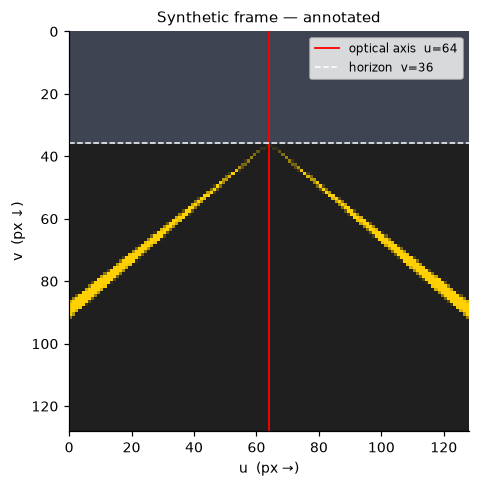

In [5]:
# Render one synthetic track frame
track = SyntheticTrack()
frame = track.render()
H, W = frame.shape[:2]

print(f'frame shape : {frame.shape}  dtype: {frame.dtype}')
print(f'horizon row : v = {track.v_horizon:.1f}')
print(f'optical axis: u = {W/2}')

# Annotate the frame so the coordinate axes are visible
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.imshow(frame, extent=(0, W, H, 0))
ax.axvline(W / 2,          color='red',   lw=1.2, label=f'optical axis  u={W//2}')
ax.axhline(track.v_horizon, color='white', lw=1.0, ls='--', label=f'horizon  v={track.v_horizon:.0f}')
ax.set(xlabel='u  (px →)', ylabel='v  (px ↓)', title='Synthetic frame — annotated')
ax.legend(fontsize=8)
ax.grid(False)
plt.tight_layout()
plt.show()


## 2 · Perspective — why parallel lines converge

The lane boundaries are parallel on the ground, but in the image they appear to meet at a point.
This is not an illusion — it is geometry we can use.

**The pinhole camera equation** maps a 3-D ground point to a pixel column:

```
u  =  W/2  +  focal * x_world / z
```

| symbol | meaning |
|--------|---------|
| `W/2` | optical centre (where the car points) |
| `focal` | focal length in pixels |
| `x_world` | lateral position on the ground (m, positive = right) |
| `z` | distance ahead on the ground (m) |

Dividing by `z` is **why** lines converge: the further away (`z` larger), the smaller the
pixel offset from the centre. At `z → ∞` both lines collapse to `u = W/2`.

**Two consequences the detector exploits:**
1. Track width in pixels is *linear* in `v` and reaches zero at the horizon.
2. Each row `v` maps to a unique distance `z` — so a pixel column converts to metres.

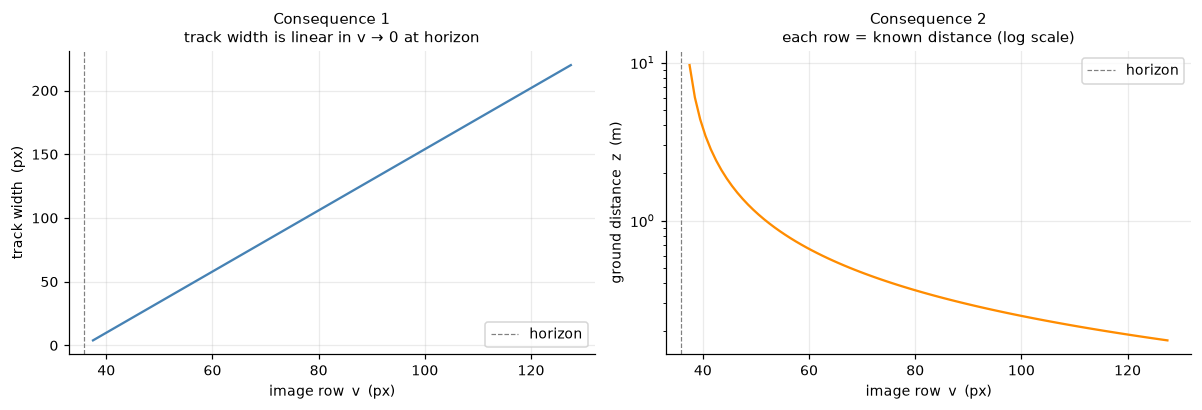

Close  (bottom): row=128  z=0.17 m  width=220.0 px
Far (near horiz): row=42  z=2.8 m  width=13.6 px


In [3]:
# Step 1 — which rows show ground?
# np.arange gives edge indices; +0.5 converts to pixel centres
rows = np.arange(int(track.v_horizon) + 2, H) + 0.5

# Step 2 — map each row to real-world distance z (metres)
z = track.distance(rows)

# Step 3 — project the left and right lane lines using the pinhole equation
#   left  boundary: x_world = centre_x - half_width
#   right boundary: x_world = centre_x + half_width
u_left  = W / 2 + track.focal * (track.centre_x(z) - track.half_width) / z
u_right = W / 2 + track.focal * (track.centre_x(z) + track.half_width) / z

# Step 4 — plot the two consequences
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

# Left: track width in pixels at each row
axes[0].plot(rows, u_right - u_left, color='steelblue')
axes[0].axvline(track.v_horizon, color='gray', ls='--', lw=0.8, label='horizon')
axes[0].set(
    xlabel='image row  v  (px)',
    ylabel='track width  (px)',
    title='Consequence 1\ntrack width is linear in v → 0 at horizon',
)
axes[0].legend()

# Right: real-world distance for each row
axes[1].plot(rows, z, color='darkorange')
axes[1].axvline(track.v_horizon, color='gray', ls='--', lw=0.8, label='horizon')
axes[1].set(
    xlabel='image row  v  (px)',
    ylabel='ground distance  z  (m)',
    title='Consequence 2\neach row = known distance (log scale)',
    yscale='log',
)
axes[1].legend()

plt.tight_layout()
plt.show()

# Concrete numbers: compare a close row vs a far row
print('Close  (bottom):',
      f'row={rows[-1]:.0f}  z={z[-1]:.2f} m  width={u_right[-1]-u_left[-1]:.1f} px')
print('Far (near horiz):',
      f'row={rows[4]:.0f}  z={z[4]:.1f} m  width={u_right[4]-u_left[4]:.1f} px')


## 3 · Colour — why yellow paint is easy to find

Sample three pixels from the frame: asphalt, a lane line, and the sky background.
We expect:

| surface | R | G | B | pattern |
|---------|---|---|---|---------|
| asphalt | mid | mid | mid | R ≈ G ≈ B (grey) |
| **paint** | **high** | **high** | **low** | R+G >> B (yellow) |
| background | low | low | low | R ≈ G ≈ B (dark grey) |

The score `R + G - 2*B` is large for yellow, near zero for grey. No neural network needed.

In [6]:
# Pick a row 30 px below the horizon — close enough to be sharp
row_sample = int(track.v_horizon + 30)

# Find the pixel column of the left line at that row
idx = np.searchsorted(rows, row_sample + 0.5)  # index into our rows array
col_line = int(u_left[idx])

# Sample the three surfaces
pixels = {
    'asphalt (mid-road)' : frame[row_sample, W // 2],
    'lane line (yellow)' : frame[row_sample, col_line],
    'background (sky)'   : frame[5, 5],
}

rows_data = []
for name, p in pixels.items():
    R, G, B = int(p[0]), int(p[1]), int(p[2])
    rows_data.append({
        'pixel'    : name,
        'R'        : R,
        'G'        : G,
        'B'        : B,
        'R+G-2B'   : R + G - 2 * B,  # the yellow detector score
    })

table(rows_data)


pixel,R,G,B,R+G-2B
asphalt (mid-road),31,31,31,0
lane line (yellow),255,209,0,464
background (sky),62,68,82,-34


## Summary

| what we learned | used in lab |
|-----------------|-------------|
| frame = `(H, W, 3)` uint8, axes `v` down / `u` right | every lab |
| `u = W/2 + focal*x/z` — pinhole equation | 04 camera |
| track width linear in `v` → 0 at horizon | 03 scan, 04 camera |
| each row = known z → pixels convert to metres | 04 camera |
| yellow score = `R + G - 2B` | 02 mask |

**Next: Lab 02 — build the colour mask that turns these insights into a binary paint/no-paint image.**